# AE 370 Group 21 Code


Run cells from top to bottom. State order: `[h, v, gamma, s]`, with `s` in meters and angles in radians. Physical parameters and study settings are defined once. Euler is the production integrator; RK4 is retained only as the existing numerical reference. The existing 150-km skip threshold is preserved.


In [16]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# Atmospheric Entry Simulation Parameters
# --- Physical Constants ---
R_E = 6378137.0         # Radius of Earth (meters)
g0 = 9.80665            # Standard gravity at sea level (m/s^2)

# --- Atmospheric & Aerodynamic Assumptions ---
rho_0 = 1.225           # Sea-level atmospheric density (kg/m^3)
H_scale = 7500.0        # Atmospheric scale height (meters)
mass = 9300.0           # Spacecraft mass (kg)
area = 10.0             # Reference frontal area (m^2)
C_D = 0.8               # Baseline drag coefficient
C_L = 0.24              # Baseline lift coefficient
L_D = 0.3               # Lift to Drag ratio
def get_density(h):
    """Calculates atmospheric density using an exponential model assumption."""
    return rho_0 * math.exp(-h / H_scale) if h >= 0 else rho_0

def calc_forces_and_load(h, v):
    """Calculates lift, drag, and the total load factor in Earth g's."""
    rho = get_density(h)
    q = 0.5 * rho * (v**2)  # Dynamic pressure
    
    lift = q * C_L * area
    drag = q * C_D * area
    load_g = np.sqrt(lift**2 + drag**2) / (mass * g0)
    
    return lift, drag, load_g

# Derived from the same gravity law used in the equations of motion.
mu = g0 * R_E**2

# Shared study settings: baseline, convergence, sweep, and plots use these.
dt = 0.025
skip_altitude = 150000.0
load_limit = 9.0
angle_tolerance = 0.001

In [18]:
def entry_equations_of_motion(t, state):
    """
    Defines the 4 ODE derivatives for the state vector: [h, v, gamma, s]
    where s is the downrange distance traveled over the Earth's surface.
    """
    h, v, gamma, s = state
    
    # Fetch forces
    lift, drag, _ = calc_forces_and_load(h, v)
    g = g0 * (R_E / (R_E + h))**2  # Gravity variation with altitude
    
    # 1. Altitude derivative
    dh_dt = v * math.sin(gamma)
    
    # 2. Velocity derivative
    dv_dt = -(drag / mass) - g * math.sin(gamma)
    
    # 3. Flight-path angle derivative
    dgamma_dt = (lift / (mass * v)) + ((v / (R_E + h)) - (g / v)) * math.cos(gamma)
    
    # 4. Downrange distance derivative (The 4th State)
    ds_dt = (R_E / (R_E + h)) * v * math.cos(gamma)
    
    return [dh_dt, dv_dt, dgamma_dt, ds_dt]

In [19]:
# --- Initial Value Problem (IVP) Conditions ---
h_0 = 120000.0          # Entry interface altitude (120 km)
v_0 = 11200.0           # Escape velocity entry speed (m/s)
gamma_0 = np.radians(-6.0) # Entry angle converted to radians
s_0 = 0.0               # Initial downrange distance (meters)

initial_state = [h_0, v_0, gamma_0, s_0]
t_span = (0, 2000)      # Max simulation window (seconds)

In [20]:
def crash_event(t, state):
    """Surface threshold; the shared Euler solver checks it at step endpoints."""
    return state[0]

crash_event.terminal = True
crash_event.direction = -1

def skip_event(t, state):
    """Shared altitude threshold; descent and upward motion are also required."""
    return state[0] - skip_altitude

skip_event.terminal = True
skip_event.direction = 1
event_thresholds = [crash_event, skip_event]

## Forward Euler solver

For each step, $y_{n+1}=y_n+\Delta t f(t_n,y_n)$. All four variables use the same old state. The final step is shortened to reach the requested end time. Returned states have shape `(number_of_times, number_of_variables)`.

Stopping conditions are checked at step endpoints. Crossing time has a time-step-sized uncertainty; use step refinement before reporting boundaries. Local one-step error is $O(\Delta t^2)$ and global error is $O(\Delta t)$ for a smooth problem in the convergence regime.

In [21]:
def forward_euler(f, initial_state, t_span, dt,
                  skip_altitude=skip_altitude, stop_on_events=True):
    """Return (states, times, outcome); states are [h, v, gamma, s].

    Events use the original endpoint-based rules. Set stop_on_events=False
    for fixed-time mathematical verification problems, not entry classification.
    """
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("dt must be positive and finite.")
    t, t_end = map(float, t_span)
    if not np.isfinite([t, t_end]).all() or t_end < t:
        raise ValueError("t_span must be finite with end >= start.")
    state = np.asarray(initial_state, dtype=float).copy()
    if state.shape != (4,) or not np.isfinite(state).all():
        raise ValueError("initial_state must contain four finite values.")
    if not np.isfinite(skip_altitude):
        raise ValueError("skip_altitude must be finite.")

    n_max = int(np.ceil((t_end - t) / dt)) + 2
    states = np.empty((n_max, 4))
    times = np.empty(n_max)
    states[0], times[0] = state, t
    count = 1
    entry_altitude = state[0]
    has_descended = False
    outcome = "unresolved"

    while True:
        if not all(math.isfinite(value) for value in state):
            outcome = "numerical failure"
            break
        h, v, gamma, s = state
        if stop_on_events:
            if v <= 0:
                outcome = "numerical failure"
                break
            if h <= 0:
                outcome = "surface"
                break
            has_descended = has_descended or h < entry_altitude
            if has_descended and h >= skip_altitude and math.sin(gamma) > 0:
                outcome = "skip"
                break
        if t >= t_end:
            break
        step = min(dt, t_end - t)
        derivatives = np.asarray(f(t, state), dtype=float)
        if derivatives.shape != state.shape:
            raise ValueError("The RHS must return one derivative per state.")
        state = state + step * derivatives
        # Avoid an extra tiny step caused by floating-point accumulation.
        new_t = t + step
        t = t_end if t_end - new_t <= 1e-12 * max(1.0, abs(t_end)) else new_t
        states[count], times[count] = state, t
        count += 1

    return states[:count], times[:count], outcome

In [22]:
states, times, outcome = forward_euler(
    entry_equations_of_motion, initial_state, t_span, dt,
    skip_altitude=skip_altitude
)
h, v, gamma, s = states.T
print("Outcome:", outcome)

Outcome: skip


independent checks of the skip-entry code

Convergence alone shows the code is consistent; it does not show the equations are right (a wrong equation converges just as cleanly). So every check here compares against something we know independently of model and euler

In [23]:
# Compatibility names for the verification/convergence sections.
# All values come from the parameter cells above; no external modules are needed.
MU, G0 = mu, g0
RHO0, H_SCALE = rho_0, H_scale
MASS, AREA, CD, CL = mass, area, C_D, C_L
H0, V0, GAMMA0 = h_0, v_0, gamma_0
T_MAX = float(t_span[1] - t_span[0])

def team_rhs(state):
    return np.asarray(entry_equations_of_motion(0.0, state), dtype=float)

def team_load(state):
    return float(calc_forces_and_load(state[0], state[1])[2])

def team_euler(rhs, state0, dt, n_steps):
    """Fixed-step adapter to the SAME Euler solver used for baseline and sweep."""
    if int(n_steps) != n_steps or n_steps < 0:
        raise ValueError("n_steps must be a nonnegative integer.")
    history, _, status = forward_euler(
        lambda t, state: rhs(state), state0, (0.0, n_steps * dt), dt,
        stop_on_events=False
    )
    if status == "numerical failure":
        raise FloatingPointError("Nonfinite state in fixed-time verification.")
    return history
# =====================================================================================


# ---------------------------------------------------------------- independent reference tools
def ref_rhs(state, g_on=1.0, cl=CL):
    """Second implementation of the equations of motion, written straight from the report.
    g_on = 0 switches off gravity AND the curvature term (flat-Earth, no-gravity limit)."""
    h, V, gam, _ = state
    r = R_E + h
    g = MU / r**2
    q = 0.5 * RHO0 * np.exp(-h / H_SCALE) * V * V
    D, L = q * CD * AREA, q * cl * AREA
    return np.array([V * np.sin(gam),
                     -D / MASS - g_on * g * np.sin(gam),
                     L / (MASS * V) + g_on * (V / r - g / V) * np.cos(gam),
                     R_E * V * np.cos(gam) / r])


def ref_load(state):
    h, V = state[0], state[1]
    q = 0.5 * RHO0 * np.exp(-h / H_SCALE) * V * V
    return q * AREA * np.hypot(CD, CL) / (MASS * G0)


def euler_step(state, dt):
    """One forward-Euler step of the team model. Check 1 shows this equals Euler solver's marching."""
    return state + dt * team_rhs(state)


def rk4_step(f, s, dt):
    k1 = f(s); k2 = f(s + 0.5 * dt * k1); k3 = f(s + 0.5 * dt * k2); k4 = f(s + dt * k3)
    return s + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6.0


def march(step, s0, T, dt):
    """March to exactly T, shortening the final step when necessary."""
    if dt <= 0 or not np.isfinite(dt) or T < 0 or not np.isfinite(T):
        raise ValueError("Require finite T >= 0 and finite dt > 0.")
    n = int(np.ceil(T / dt - 1e-12))
    hist = np.empty((n + 1, len(s0)))
    hist[0] = s0
    for k in range(n):
        hist[k + 1] = step(hist[k], min(dt, T - k * dt))
    return hist


def specific_energy(s):
    return 0.5 * s[..., 1] ** 2 - MU / (R_E + s[..., 0])


def ang_momentum(s):
    return (R_E + s[..., 0]) * s[..., 1] * np.cos(s[..., 2])


def tail_slope(dts, errs, k=4):
    """Observed order from the k finest step sizes (the asymptotic regime)."""
    dts, errs = np.asarray(dts, float), np.asarray(errs, float)
    valid = np.isfinite(dts) & np.isfinite(errs) & (dts > 0) & (errs > 0)
    dts, errs = dts[valid], errs[valid]
    if len(dts) < 2:
        return np.nan
    idx = np.argsort(dts)[:k]
    return np.polyfit(np.log(dts[idx]), np.log(errs[idx]), 1)[0]


DTS = np.array([0.4, 0.2, 0.1, 0.05, 0.025, 0.0125])
S0 = np.array([H0, V0, GAMMA0, 0.0])
RESULTS = []


def report(name, passed, detail):
    RESULTS.append((name, passed))
    print(f"  [{'PASS' if passed else 'FAIL'}] {name}: {detail}")


def table(header, rows):
    print("    " + "  ".join(f"{h:>15}" for h in header))
    for r in rows:
        print("    " + "  ".join(f"{x:15.6g}" for x in r))


# ---------------------------------------------------------------- 1. Euler solver
def check_euler():
    print("\n1. Euler solver against closed-form results")
    s0 = np.array([1.0, 2.0, 3.0, 4.0])
    # (a) y' = -lam*y. Forward Euler gives exactly y_n = (1 - lam*dt)^n y_0.
    lam, dt, n = 2.0, 0.05, 40
    got = team_euler(lambda s: -lam * s, s0, dt, n)[-1]
    err = np.max(np.abs(got - s0 * (1 - lam * dt) ** n) / np.abs(s0))
    report("exact discrete map, decay", err < 1e-12, f"max rel. diff = {err:.1e}")
    # (b) x'' = -w^2 x. Forward Euler multiplies the amplitude^2 by exactly (1 + (w dt)^2) per step.
    w, dt, n = 3.0, 0.02, 100
    osc = lambda s: np.array([s[1], -w * w * s[0], 0.0, 0.0])
    s = team_euler(osc, np.array([1.0, 0.0, 0.0, 0.0]), dt, n)[-1]
    amp2 = s[0] ** 2 + (s[1] / w) ** 2
    err = abs(amp2 / (1 + (w * dt) ** 2) ** n - 1)
    report("exact discrete map, oscillator", err < 1e-10, f"amplitude growth matches (1+(w dt)^2)^n, rel. diff = {err:.1e}")
    # (c) order of accuracy against the true solution of y' = -lam*y
    T = 2.0
    errs = [abs(team_euler(lambda s: -lam * s, s0, d, int(round(T / d)))[-1][0] - np.exp(-lam * T)) for d in DTS]
    p = tail_slope(DTS, errs)
    report("order on y' = -lam*y", 0.9 < p < 1.1, f"observed slope = {p:.3f} (expect 1)")
    # (d) Euler solver on the real model equals the plain recursion s + dt*f(s)
    dt, n = 0.05, 2000
    a = team_euler(team_rhs, S0, dt, n)[-1]
    b = S0.copy()
    for _ in range(n):
        b = euler_step(b, dt)
    err = np.max(np.abs(a - b) / np.maximum(np.abs(b), 1e-12))
    report("Euler solver equals s + dt*f(s) on model cells", err < 1e-9, f"max rel. diff after {n} steps = {err:.1e}")


# ---------------------------------------------------------------- 2. model cells vs second implementation
def check_model():
    print("\n2. model cells against an independent implementation of the equations")
    rng = np.random.default_rng(0)
    states = [S0] + [np.array([rng.uniform(0, 122e3), rng.uniform(500, 11500),
                               np.deg2rad(rng.uniform(-20, 20)), 0.0]) for _ in range(300)]
    worst, worst_load = 0.0, 0.0
    for s in states:
        a, b = team_rhs(s), ref_rhs(s)
        worst = max(worst, np.max(np.abs(a - b) / np.maximum(np.abs(b), 1e-10)))
        worst_load = max(worst_load, abs(team_load(s) - ref_load(s)) / max(ref_load(s), 1e-300))
    report("state derivatives", worst < 1e-9, f"max rel. diff over {len(states)} states = {worst:.1e}")
    report("load factor (g)", worst_load < 1e-9, f"max rel. diff = {worst_load:.1e}")


# ---------------------------------------------------------------- 3. vacuum conservation
def check_vacuum():
    print("\n3. Vacuum limit (start at 600 km where density is ~1e-36 kg/m^3): energy and angular momentum conserved")
    s0 = np.array([600e3, V0, GAMMA0, 0.0])
    e0, l0 = specific_energy(s0), ang_momentum(s0)
    rows = []
    for dt in DTS:
        s = team_euler(team_rhs, s0, dt, int(round(300.0 / dt)))[-1]
        rows.append((dt, abs(specific_energy(s) - e0) / abs(e0), abs(ang_momentum(s) - l0) / l0))
    rows = np.array(rows)
    table(["dt [s]", "rel energy err", "rel h-mom err"], rows)
    pe, pl = tail_slope(rows[:, 0], rows[:, 1]), tail_slope(rows[:, 0], rows[:, 2])
    report("conserved quantities", 0.9 < pe < 1.1 and 0.9 < pl < 1.1 and rows[-1, 1] < 1e-5,
           f"slopes: energy {pe:.2f}, angular momentum {pl:.2f} (expect 1); error -> 0 as dt -> 0")
    return rows


# ---------------------------------------------------------------- 4. Allen-Eggers
def check_allen_eggers():
    print("\n4. Allen-Eggers limit: no gravity, no lift, straight path")
    gam0, T = np.deg2rad(-10.0), 80.0
    s0 = np.array([H0, V0, gam0, 0.0])
    f = lambda s: ref_rhs(s, g_on=0.0, cl=0.0)
    beta = MASS / (CD * AREA)
    rho = lambda h: RHO0 * np.exp(-h / H_SCALE)
    a_exact = (-V0**2 * np.sin(gam0) / (2 * np.e * H_SCALE)
               * np.exp(-H_SCALE * RHO0 * np.exp(-H0 / H_SCALE)
                        / (beta * np.sin(gam0))))          # peak deceleration
    rows = []
    for dt in DTS:
        S = march(lambda s, d: s + d * f(s), s0, T, dt)
        decel = 0.5 * rho(S[:, 0]) * S[:, 1] ** 2 / beta
        V_ex = V0 * np.exp(H_SCALE * (rho(S[:, 0]) - rho(H0)) / (2 * beta * np.sin(gam0)))   # V(h)
        rows.append((dt, abs(decel.max() - a_exact) / a_exact, np.max(np.abs(S[:, 1] - V_ex)) / V0))
    rows = np.array(rows)
    table(["dt [s]", "peak-decel err", "max|V-V_AE|/V0"], rows)
    p = tail_slope(rows[:, 0], rows[:, 2])
    report("Allen-Eggers V(h) and peak deceleration", 0.9 < p < 1.15 and rows[-1, 1] < 0.01,
           f"V(h) slope {p:.2f} (expect 1); peak decel within {rows[-1,1]*100:.2f}% at dt={DTS[-1]} s")
    return rows


# ---------------------------------------------------------------- 5. whole pipeline vs independent RK4
def check_pipeline(T=100.0):
    print(f"\n5. model cells + Euler solver vs independent RK4 on independently coded equations (t = {T:.0f} s, baseline entry)")
    ref = march(lambda s, d: rk4_step(ref_rhs, s, d), S0, T, 0.05)[-1]
    ref2 = march(lambda s, d: rk4_step(ref_rhs, s, d), S0, T, 0.1)[-1]
    ref_gap = np.abs(ref - ref2)[:3]
    print(f"    reference check, RK4 dt=0.1 vs 0.05 differ by dh={ref_gap[0]:.1e} m, dV={ref_gap[1]:.1e} m/s")
    rows = []
    for dt in np.array([1.6, 0.8, 0.4, 0.2, 0.1, 0.05, 0.025, 0.0125]):
        s = march(lambda state, step: euler_step(state, step), S0, T, dt)[-1]
        rows.append((dt, *np.abs(s - ref)[:3]))
    rows = np.array(rows)
    table(["dt [s]", "|dh| [m]", "|dV| [m/s]", "|dgamma| [rad]"], rows)
    ps = [tail_slope(rows[:, 0], rows[:, j]) for j in (1, 2, 3)]
    ok = all(0.85 < p < 1.15 for p in ps) and rows[-1, 2] < 1.0
    report("pipeline converges to the independent solution", ok,
           f"slopes h {ps[0]:.2f}, V {ps[1]:.2f}, gamma {ps[2]:.2f} (expect 1); |dV| = {rows[-1,2]:.2g} m/s at dt = {rows[-1,0]} s")
    return rows


def run_all():
    print("Verification -- baseline: h0 = %.2f km, V0 = %.3f km/s, gamma0 = %.2f deg" %
          (H0 / 1e3, V0 / 1e3, np.rad2deg(GAMMA0)))
    RESULTS.clear()
    check_euler()
    check_model()
    check_vacuum()
    check_allen_eggers()
    check_pipeline()
    n_fail = sum(not ok for _, ok in RESULTS)
    print(f"\n{len(RESULTS) - n_fail}/{len(RESULTS)} checks passed")
    return n_fail


# Notebook execution: report failures without terminating the kernel.
verification_failures = run_all()

Verification -- baseline: h0 = 120.00 km, V0 = 11.200 km/s, gamma0 = -6.00 deg

1. Euler solver against closed-form results
  [PASS] exact discrete map, decay: max rel. diff = 1.9e-17
  [PASS] exact discrete map, oscillator: amplitude growth matches (1+(w dt)^2)^n, rel. diff = 5.9e-15
  [PASS] order on y' = -lam*y: observed slope = 0.968 (expect 1)
  [PASS] Euler solver equals s + dt*f(s) on model cells: max rel. diff after 2000 steps = 0.0e+00

2. model cells against an independent implementation of the equations
  [PASS] state derivatives: max rel. diff over 301 states = 2.1e-14
  [PASS] load factor (g): max rel. diff = 4.5e-16

3. Vacuum limit (start at 600 km where density is ~1e-36 kg/m^3): energy and angular momentum conserved
             dt [s]   rel energy err    rel h-mom err
                0.4       1.5864e-05      4.75195e-05
                0.2      7.93593e-06      2.37587e-05
                0.1      3.96894e-06      1.18791e-05
               0.05      1.98471e-06     

Convergence -- baseline: h0 = 120.00 km, V0 = 11.200 km/s, gamma0 = -6.00 deg

baseline (Euler, dt=0.05): outcome = skip, peak load 3.01 g at t = 93.7 s

A. State error at t = 187.2 s
             dt [s]         |dh| [m]       |dV| [m/s]   |dgamma| [rad]
                1.6          236.778          123.407       0.00140793
                0.8          104.145          60.4017      0.000686336
                0.4           48.581          29.8869      0.000338917
                0.2          23.4262          14.8664      0.000168414
                0.1          11.4981          7.41406      8.39483e-05
               0.05           5.6954          3.70227      4.19097e-05
              0.025          2.83431          1.84995      2.09388e-05
    observed order: h 1.02, V 1.00, gamma 1.00  (forward Euler: expect 1)

B. Peak aerodynamic load, baseline entry angle
    reference (RK4, dt=0.1): peak load = 3.0047 g at t = 93.8 s, outcome = skip
             dt [s]    peak load [g]       rel

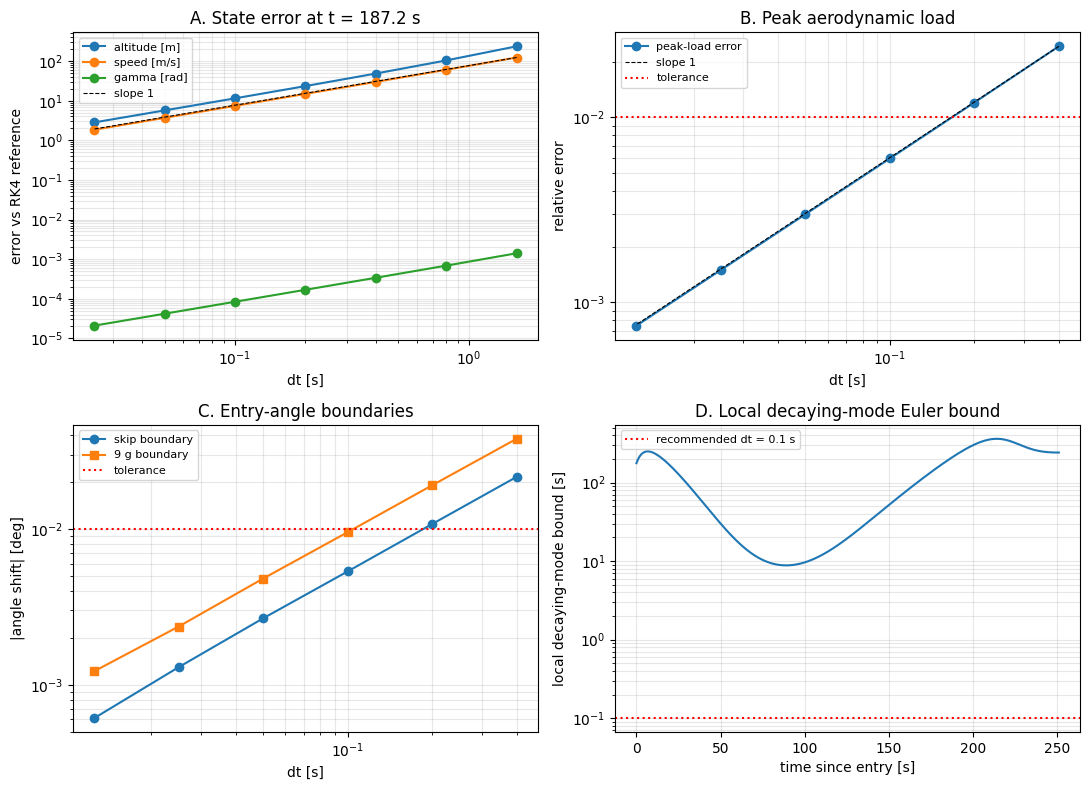


Convergence results are kept in convergence_results; plot displayed below this cell.


In [24]:
import os

LOAD_LIMIT_G = load_limit     # [g] load threshold used in the study
TOL_PEAK = 0.01                                    # accept <= 1 % error in peak load
TOL_BOUNDARY_DEG = 0.01                            # accept <= 0.01 deg shift in a boundary angle
BRACKET_DEG = (-12.0, -2.0)                        # steep end (no skip) .. shallow end (skip)
REF_DT = 0.1                                       # RK4 reference step [s]


# ---------------------------------------------------------------- single entry run with events
def run_entry(gamma0, V0_=V0, dt=0.05, method="euler"):
    """Shared entry rules: surface, upward 150-km skip after descent, or timeout.

    Euler is the production method. The existing from-scratch RK4 is only a
    numerical reference for verification/convergence, not the study integrator.
    """
    if method not in ("euler", "rk4"):
        raise ValueError("method must be 'euler' or 'rk4'.")
    if method == "euler":
        advance_rhs = entry_equations_of_motion
    else:
        # An effective slope lets the common time/event loop advance RK4.
        advance_rhs = lambda t, state: (rk4_step(team_rhs, state, dt) - state) / dt
    state0 = np.array([H0, V0_, gamma0, s_0], dtype=float)
    if method == "rk4":
        # Reference dt divides the shared time window in all study calls.
        if not np.isclose(T_MAX / dt, round(T_MAX / dt)):
            raise ValueError("RK4 reference dt must divide the simulation window.")
    history, run_times, status = forward_euler(
        advance_rhs, state0, t_span, dt, skip_altitude=skip_altitude
    )
    valid = np.all(np.isfinite(history), axis=1) & (history[:, 1] > 0)
    valid_history = history[valid]
    loads = np.array([team_load(state) for state in valid_history])
    i = int(np.argmax(loads)) if len(loads) else 0
    return dict(skip=status == "skip", peak=float(loads[i]) if len(loads) else np.nan,
                t_peak=float(run_times[valid][i]) if len(loads) else np.nan,
                t_end=float(run_times[-1]), outcome=status,
                min_altitude=float(np.min(history[valid, 0])) if valid.any() else np.nan)


def bisect_angle(pred, lo_deg, hi_deg, tol_deg=1e-4):
    """pred(gamma_rad) is False at the steep end and True at the shallow end. Returns the flip angle [deg]
    (nan if the bracket does not contain a flip)."""
    f = lambda a: pred(np.deg2rad(a))
    if f(lo_deg) or not f(hi_deg):
        return np.nan
    while hi_deg - lo_deg > tol_deg:
        mid = 0.5 * (lo_deg + hi_deg)
        lo_deg, hi_deg = (lo_deg, mid) if f(mid) else (mid, hi_deg)
    return 0.5 * (lo_deg + hi_deg)


# ---------------------------------------------------------------- A. state error at fixed time
def study_state(dts, T):
    ref = march(lambda s, d: rk4_step(team_rhs, s, d), S0, T, REF_DT)[-1]
    rows = []
    for dt in dts:
        s = march(lambda s_, d: euler_step(s_, d), S0, T, dt)[-1]
        rows.append((dt, *np.abs(s - ref)[:3]))
    rows = np.array(rows)
    table(["dt [s]", "|dh| [m]", "|dV| [m/s]", "|dgamma| [rad]"], rows)
    p = [tail_slope(rows[:, 0], rows[:, j]) for j in (1, 2, 3)]
    print(f"    observed order: h {p[0]:.2f}, V {p[1]:.2f}, gamma {p[2]:.2f}  (forward Euler: expect 1)")
    return rows


# ---------------------------------------------------------------- B. peak load vs dt
def study_peak(dts):
    ref = run_entry(GAMMA0, dt=REF_DT, method="rk4")
    q = np.array([run_entry(GAMMA0, dt=dt)["peak"] for dt in dts])
    err = np.abs(q - ref["peak"]) / ref["peak"]
    # Richardson extrapolation (p = 1) from consecutive step sizes: Q_inf ~ Q_f + (Q_f - Q_c)/(r - 1), r = dt_c/dt_f
    r = dts[:-1] / dts[1:]
    q_rich = q[1:] + (q[1:] - q[:-1]) / (r - 1)
    print(f"    reference (RK4, dt={REF_DT}): peak load = {ref['peak']:.4f} g at t = {ref['t_peak']:.1f} s, outcome = {ref['outcome']}")
    rows = np.column_stack([dts, q, err, np.r_[np.nan, q_rich]])
    table(["dt [s]", "peak load [g]", "rel. error", "Richardson Q_inf"], rows)
    print(f"    observed order of peak-load error: {tail_slope(dts, err):.2f}")
    return rows, ref


# ---------------------------------------------------------------- C. boundary angles vs dt
def study_boundaries(dts):
    def both(dt, method):
        skip = bisect_angle(lambda g: run_entry(g, dt=dt, method=method)["skip"], *BRACKET_DEG)
        load = bisect_angle(lambda g: run_entry(g, dt=dt, method=method)["peak"] <= LOAD_LIMIT_G, *BRACKET_DEG)
        return skip, load
    ref_skip, ref_load = both(REF_DT, "rk4")
    print(f"    reference (RK4, dt={REF_DT}): skip boundary = {ref_skip:.4f} deg, {LOAD_LIMIT_G:g} g boundary = {ref_load:.4f} deg")
    rows = []
    for dt in dts:
        s_b, l_b = both(dt, "euler")
        rows.append((dt, s_b, s_b - ref_skip, l_b, l_b - ref_load))
    rows = np.array(rows)
    table(["dt [s]", "skip bdry [deg]", "shift [deg]", "load bdry [deg]", "shift [deg]"], rows)
    return rows, (ref_skip, ref_load)


# ---------------------------------------------------------------- D. stability estimate
def jacobian(s):
    J = np.zeros((4, 4))
    for j, scale in enumerate([1e3, 1e3, 0.1, 1.0]):
        e = 1e-6 * max(abs(s[j]), scale)
        sp, sm = s.copy(), s.copy()
        sp[j] += e
        sm[j] -= e
        J[:, j] = (team_rhs(sp) - team_rhs(sm)) / (2 * e)
    return J


def study_stability(stride=10):
    """Forward Euler is stable for a mode lambda when |1 + lambda dt| < 1, i.e. dt < -2 Re(lambda)/|lambda|^2.
    Linearize along the reference trajectory and take the most restrictive decaying mode.
    This diagnostic is NOT a global stability guarantee for a varying Jacobian.
    Neutral and growing modes are not certified by this bound."""
    ref = run_entry(GAMMA0, dt=REF_DT, method="rk4")
    n = int(round(ref["t_end"] / REF_DT))
    hist = march(lambda s, d: rk4_step(team_rhs, s, d), S0, n * REF_DT, REF_DT)
    t, lim = [], []
    for k in range(0, n + 1, stride):
        lam = np.linalg.eigvals(jacobian(hist[k]))
        lam = lam[lam.real < -1e-12]
        t.append(k * REF_DT)
        lim.append(np.min(-2 * lam.real / np.abs(lam) ** 2) if lam.size else np.inf)
    t, lim = np.array(t), np.array(lim)
    i = int(np.argmin(lim))
    print(f"    smallest local decaying-mode dt bound along the baseline: {lim[i]:.3g} s (at t = {t[i]:.0f} s)")
    return np.column_stack([t, lim]), lim[i]


# ---------------------------------------------------------------- E. recommendation
def recommend(peak_rows, bdry_rows, dt_stab):
    ok = (peak_rows[:, 2] <= TOL_PEAK) & (np.abs(bdry_rows[:, 2]) <= TOL_BOUNDARY_DEG) \
         & (np.abs(bdry_rows[:, 4]) <= TOL_BOUNDARY_DEG)
    dts = peak_rows[:, 0]
    ok &= dts < dt_stab
    order = np.argsort(dts)[::-1]                    # coarse -> fine
    good = None
    for i in order:                                  # largest dt such that it AND every finer dt pass
        if all(ok[dts <= dts[i]]):
            good = dts[i]
            break
    print(f"\nE. Tolerances: peak load <= {TOL_PEAK*100:g} %, boundary angles <= {TOL_BOUNDARY_DEG:g} deg")
    if good is None:
        print("   No tested dt meets the tolerances -- extend the dt list to smaller steps.")
    else:
        print(f"   Recommended dt = {good:g} s  ({int(round(100.0 / good))} steps per 100 s of flight; "
              f"{good / dt_stab * 100:.1f} % of the linear stability limit {dt_stab:.3g} s)")
    return good


def make_figure(state, peak, bdry, stab, dt_rec, T):
    fig, ax = plt.subplots(2, 2, figsize=(11, 8))
    a = ax[0, 0]
    for j, lab in zip((1, 2, 3), ("altitude [m]", "speed [m/s]", "gamma [rad]")):
        a.loglog(state[:, 0], state[:, j], "o-", label=lab)
    a.loglog(state[:, 0], state[0, 2] * state[:, 0] / state[0, 0], "k--", lw=0.8, label="slope 1")
    a.set(xlabel="dt [s]", ylabel="error vs RK4 reference", title=f"A. State error at t = {T:.1f} s")
    a.legend(fontsize=8)
    a = ax[0, 1]
    a.loglog(peak[:, 0], peak[:, 2], "o-", label="peak-load error")
    a.loglog(peak[:, 0], peak[0, 2] * peak[:, 0] / peak[0, 0], "k--", lw=0.8, label="slope 1")
    a.axhline(TOL_PEAK, color="r", ls=":", label="tolerance")
    a.set(xlabel="dt [s]", ylabel="relative error", title="B. Peak aerodynamic load")
    a.legend(fontsize=8)
    a = ax[1, 0]
    a.loglog(bdry[:, 0], np.abs(bdry[:, 2]), "o-", label="skip boundary")
    a.loglog(bdry[:, 0], np.abs(bdry[:, 4]), "s-", label=f"{LOAD_LIMIT_G:g} g boundary")
    a.axhline(TOL_BOUNDARY_DEG, color="r", ls=":", label="tolerance")
    a.set(xlabel="dt [s]", ylabel="|angle shift| [deg]", title="C. Entry-angle boundaries")
    a.legend(fontsize=8)
    a = ax[1, 1]
    a.semilogy(stab[:, 0], stab[:, 1], "-")
    if dt_rec:
        a.axhline(dt_rec, color="r", ls=":", label=f"recommended dt = {dt_rec:g} s")
        a.legend(fontsize=8)
    a.set(xlabel="time since entry [s]", ylabel="local decaying-mode bound [s]", title="D. Local decaying-mode Euler bound")
    for x in ax.ravel():
        x.grid(alpha=0.3, which="both")
    fig.tight_layout()
    plt.show()  # Display directly below this cell in the VS Code notebook.


def run_convergence(quick=False):
    dts = np.array([0.4, 0.1, 0.025]) if quick else np.array([0.4, 0.2, 0.1, 0.05, 0.025, 0.0125])
    dts_state = np.array([1.6, 0.4, 0.1, 0.025]) if quick else np.array([1.6, 0.8, 0.4, 0.2, 0.1, 0.05, 0.025])
    print(f"Convergence -- baseline: h0 = {H0/1e3:.2f} km, V0 = {V0/1e3:.3f} km/s, gamma0 = {np.rad2deg(GAMMA0):.2f} deg")

    base = run_entry(GAMMA0, dt=0.05)
    T = 1.6 * max(2, round(min(2 * base["t_peak"], base["t_end"]) / 1.6))     # fixed comparison time, covers the peak
    print(f"\nbaseline (Euler, dt=0.05): outcome = {base['outcome']}, peak load {base['peak']:.2f} g at t = {base['t_peak']:.1f} s")

    print(f"\nA. State error at t = {T:.1f} s")
    state = study_state(dts_state, T)
    print("\nB. Peak aerodynamic load, baseline entry angle")
    peak, _ = study_peak(dts)
    print("\nC. Entry-angle boundaries (bisection, 1e-4 deg)")
    bdry, refs = study_boundaries(dts)
    print("\nD. Stability")
    stab, dt_stab = study_stability()
    dt_rec = recommend(peak, bdry, dt_stab)

    make_figure(state, peak, bdry, stab, dt_rec, T)
    print("\nConvergence results are kept in convergence_results; plot displayed below this cell.")
    return dict(state=state, peak=peak, boundaries=bdry, stability=stab, dt_recommended=dt_rec)


convergence_results = run_convergence()


In [25]:
# Speeds and angle grid retained from the original sweep.
entry_speeds = [10500.0, 11000.0, 11500.0]
entry_angles = np.linspace(-10.0, -1.0, 91)

def run_one_case(v_start, gamma_start_deg, dt):
    """Use the same model, Euler solver, and event rules as the baseline."""
    case = run_entry(np.radians(gamma_start_deg), V0_=v_start, dt=dt)
    return {
        "v_start": float(v_start),
        "gamma_start_deg": float(gamma_start_deg),
        "outcome": case["outcome"],
        "max_load_g": case["peak"],
        "min_altitude_m": case["min_altitude"],
        "end_time_s": case["t_end"]
    }

In [26]:
results = []

for speed in entry_speeds:
    print(f"Running speed: {speed / 1000:.2f} km/s")

    for angle in entry_angles:
        case = run_one_case(speed, angle, dt)
        results.append(case)

print(f"\nFinished: {len(results)} trajectories.")
print("Sweep results are kept in the results list.")

Running speed: 10.50 km/s
Running speed: 11.00 km/s
Running speed: 11.50 km/s

Finished: 273 trajectories.
Sweep results are kept in the results list.


In [27]:
def refine_boundary(speed, angle_a, angle_b, boundary_type):
    """Refine a detected boundary by repeatedly halving its bracket."""

    def category(case):
        if boundary_type == "skip":
            if case["outcome"] not in ("skip", "surface"):
                return None
            return case["outcome"] == "skip"

        if boundary_type == "load":
            if case["outcome"] != "skip":
                return None
            return case["max_load_g"] <= load_limit

        raise ValueError("Unknown boundary type")

    case_a = run_one_case(speed, angle_a, dt)
    case_b = run_one_case(speed, angle_b, dt)

    category_a = category(case_a)
    category_b = category(case_b)

    if (
        category_a is None
        or category_b is None
        or category_a == category_b
    ):
        return None

    while abs(angle_b - angle_a) > angle_tolerance:
        angle_mid = 0.5 * (angle_a + angle_b)
        case_mid = run_one_case(speed, angle_mid, dt)
        category_mid = category(case_mid)

        if category_mid is None:
            return None

        if category_mid == category_a:
            angle_a = angle_mid
            case_a = case_mid
        else:
            angle_b = angle_mid
            case_b = case_mid

    return {"v_start": float(speed),
        "boundary_type": boundary_type,
        "angle_a_deg": float(angle_a),
        "angle_b_deg": float(angle_b),
        "outcome_a": case_a["outcome"],
        "outcome_b": case_b["outcome"],
        "load_a_g": float(case_a["max_load_g"]),
        "load_b_g": float(case_b["max_load_g"]),
        "dt_s": float(dt)
    }


boundary_results = []

for speed in entry_speeds:
    speed_cases = sorted(
        [case for case in results if case["v_start"] == speed],
        key=lambda case: case["gamma_start_deg"]
    )

    for case_a, case_b in zip(speed_cases[:-1], speed_cases[1:]):
        angle_a = case_a["gamma_start_deg"]
        angle_b = case_b["gamma_start_deg"]

        # Skip-to-surface boundary
        if {case_a["outcome"], case_b["outcome"]} == {"skip", "surface"}:
            boundary = refine_boundary(speed, angle_a, angle_b, "skip")

            if boundary is not None:
                boundary_results.append(boundary)

        # 9 g boundary, only when both cases are skips
        if case_a["outcome"] == "skip" and case_b["outcome"] == "skip":
            below_a = case_a["max_load_g"] <= load_limit
            below_b = case_b["max_load_g"] <= load_limit
            if below_a != below_b:
                boundary = refine_boundary(speed, angle_a, angle_b, "load")

                if boundary is not None:
                    boundary_results.append(boundary)


# Display refined boundaries
for speed in entry_speeds:
    print(f"\nInitial speed: {speed / 1000:.2f} km/s")

    found = [
        item for item in boundary_results
        if item["v_start"] == speed
    ]

    if not found:
        print("No boundary found in the sampled range.")
    else:
        for item in found:
            print(
                f"{item['boundary_type']} boundary: "
                f"{item['angle_a_deg']:.4f}° to "
                f"{item['angle_b_deg']:.4f}°"
            )

print("\nRefined boundaries are kept in boundary_results.")



Initial speed: 10.50 km/s
skip boundary: -6.4344° to -6.4336°

Initial speed: 11.00 km/s
skip boundary: -7.0398° to -7.0391°

Initial speed: 11.50 km/s
skip boundary: -7.5992° to -7.5984°
load boundary: -7.1570° to -7.1562°

Refined boundaries are kept in boundary_results.


In [28]:
# Pass the calculated boundaries directly to the plotting cell.
# The results list already contains numeric values.
boundaries = boundary_results


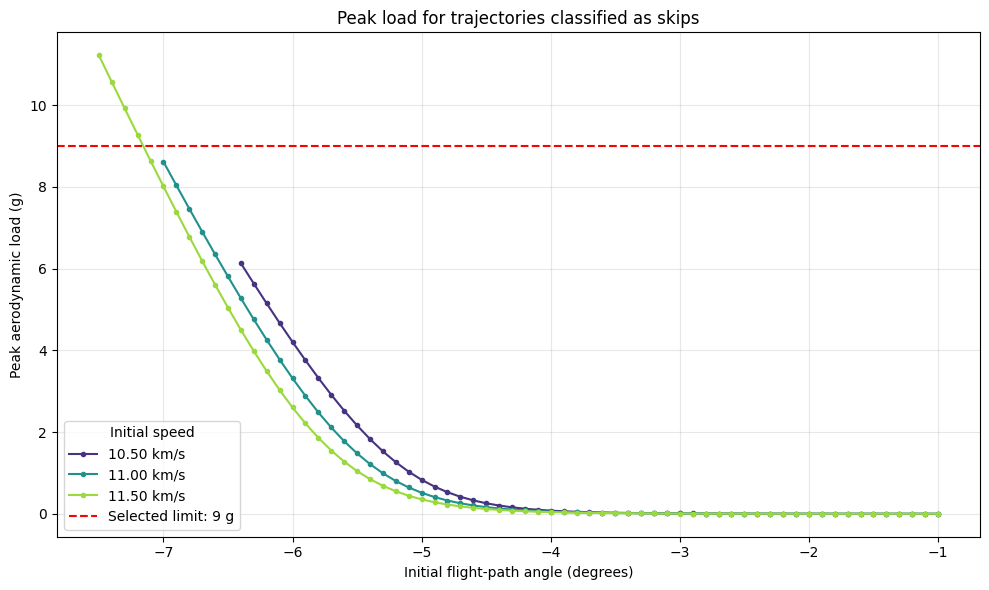

Refined boundaries:
10.50 km/s | skip boundary: -6.4344° to -6.4336°
11.00 km/s | skip boundary: -7.0398° to -7.0391°
11.50 km/s | skip boundary: -7.5992° to -7.5984°
11.50 km/s | load boundary: -7.1570° to -7.1562°


In [29]:
speeds = sorted(set(case["v_start"] for case in results))
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(speeds)))

fig, ax = plt.subplots(figsize=(10, 6))

for speed, color in zip(speeds, colors):
    cases = sorted(
        [case for case in results if case["v_start"] == speed],
        key=lambda case: case["gamma_start_deg"]
    )

    angles = [case["gamma_start_deg"] for case in cases]

    # NaN leaves non-skip trajectories off the plot.
    loads = [
        case["max_load_g"] if case["outcome"] == "skip" else np.nan
        for case in cases
    ]

    ax.plot(
        angles,
        loads,
        marker="o",
        markersize=3,
        color=color,
        label=f"{speed / 1000:.2f} km/s"
    )

ax.axhline(
    load_limit,
    color="red",
    linestyle="--",
    label=f"Selected limit: {load_limit:g} g"
)

ax.set_xlabel("Initial flight-path angle (degrees)")
ax.set_ylabel("Peak aerodynamic load (g)")
ax.set_title("Peak load for trajectories classified as skips")
ax.grid(True, alpha=0.3)
ax.legend(title="Initial speed")

plt.tight_layout()

# Display directly below this cell in the VS Code notebook.
plt.show()


# Print the refined boundaries
print("Refined boundaries:")

if not boundaries:
    print("No boundaries found in the sampled range.")
else:
    for boundary in boundaries:
        print(
            f"{boundary['v_start'] / 1000:.2f} km/s | "
            f"{boundary['boundary_type']} boundary: "
            f"{boundary['angle_a_deg']:.4f}° to "
            f"{boundary['angle_b_deg']:.4f}°"
        )

